In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
import gzip

In [2]:
dataset_path = os.path.join(os.getcwd(), "dataset")

print(dataset_path)
print(os.listdir(dataset_path))

C:\Users\Shant\Downloads\Fashion_Image_Classification\dataset
['t10k-images-idx3-ubyte.gz', 't10k-labels-idx1-ubyte.gz', 'train-images-idx3-ubyte.gz', 'train-labels-idx1-ubyte.gz']


In [3]:
def load_images(filename):
    with gzip.open(os.path.join(dataset_path, filename), 'rb') as file:
        images = np.frombuffer(file.read(), dtype=np.uint8, offset=16)
        images = images.reshape(-1, 28, 28)
    return images

In [4]:
X_train = load_images("train-images-idx3-ubyte.gz")
X_test = load_images("t10k-images-idx3-ubyte.gz")

In [5]:
def load_labels(filename):
    with gzip.open(os.path.join(dataset_path, filename), 'rb') as file:
        labels = np.frombuffer(file.read(), dtype=np.uint8, offset=8)
    return labels

In [6]:
y_train = load_labels("train-labels-idx1-ubyte.gz")
y_test = load_labels("t10k-labels-idx1-ubyte.gz")

In [7]:
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (60000, 28, 28)
X_test shape: (10000, 28, 28)
y_train shape: (60000,)
y_test shape: (10000,)


In [8]:
class_names = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot"
]

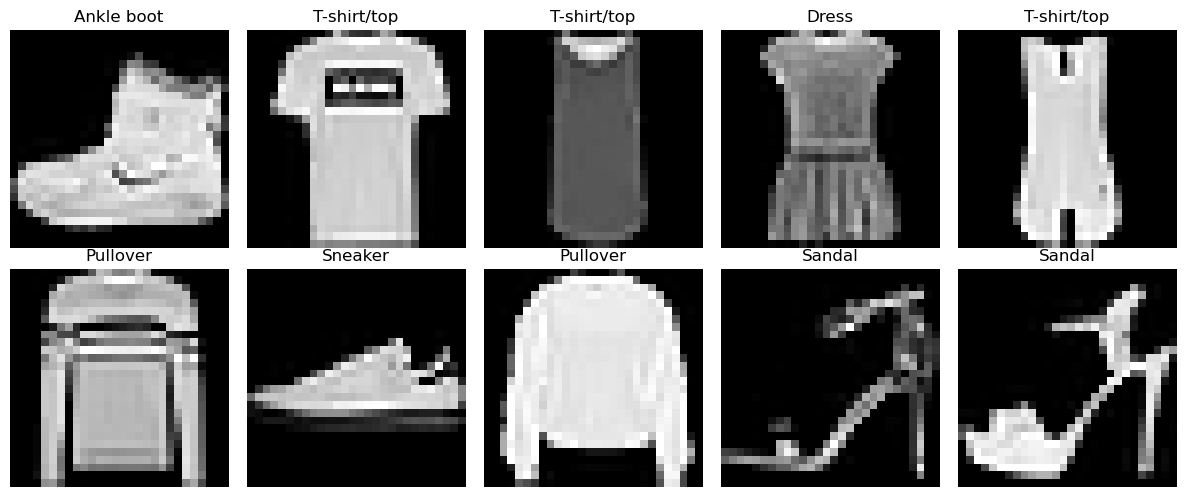

In [9]:
plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[i], cmap="gray")
    plt.title(class_names[y_train[i]])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [10]:
X_train_flat = X_train.reshape(X_train.shape[0], -1)
X_test_flat = X_test.reshape(X_test.shape[0], -1)

print("Training data shape:", X_train_flat.shape)
print("Testing data shape:", X_test_flat.shape)

Training data shape: (60000, 784)
Testing data shape: (10000, 784)


In [11]:
print("Minimum pixel value:", X_train_flat.min())
print("Maximum pixel value:", X_train_flat.max())
print("Data type:", X_train_flat.dtype)

Minimum pixel value: 0
Maximum pixel value: 255
Data type: uint8


In [12]:
X_train_scaled = X_train_flat / 255.0
X_test_scaled = X_test_flat / 255.0

print("Minimum value:", X_train_scaled.min())
print("Maximum value:", X_train_scaled.max())

Minimum value: 0.0
Maximum value: 1.0


In [13]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

In [14]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [15]:
from sklearn.model_selection import train_test_split

X_knn_train, _, y_knn_train, _ = train_test_split(
    X_train_scaled,
    y_train,
    train_size=10000,
    stratify=y_train,
    random_state=42
)

print("KNN training data:", X_knn_train.shape)
print("KNN training labels:", y_knn_train.shape)

KNN training data: (10000, 784)
KNN training labels: (10000,)


In [16]:
knn_model = KNeighborsClassifier(n_neighbors=5)

knn_model.fit(X_knn_train, y_knn_train)

,n_neighbors,5
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


In [17]:
y_pred_knn = knn_model.predict(X_test_scaled)

print(y_pred_knn[:10])

[9 2 1 1 6 1 4 6 5 7]


In [18]:
knn_accuracy = accuracy_score(y_test, y_pred_knn)

print("KNN Model Accuracy:", knn_accuracy * 100, "%")

KNN Model Accuracy: 81.51 %


In [19]:
print(classification_report(y_test, y_pred_knn, target_names=class_names))

              precision    recall  f1-score   support

 T-shirt/top       0.74      0.82      0.78      1000
     Trouser       0.99      0.95      0.97      1000
    Pullover       0.66      0.74      0.70      1000
       Dress       0.87      0.82      0.85      1000
        Coat       0.73      0.69      0.71      1000
      Sandal       0.99      0.77      0.87      1000
       Shirt       0.57      0.55      0.56      1000
     Sneaker       0.83      0.93      0.88      1000
         Bag       0.97      0.93      0.95      1000
  Ankle boot       0.86      0.96      0.91      1000

    accuracy                           0.82     10000
   macro avg       0.82      0.82      0.82     10000
weighted avg       0.82      0.82      0.82     10000



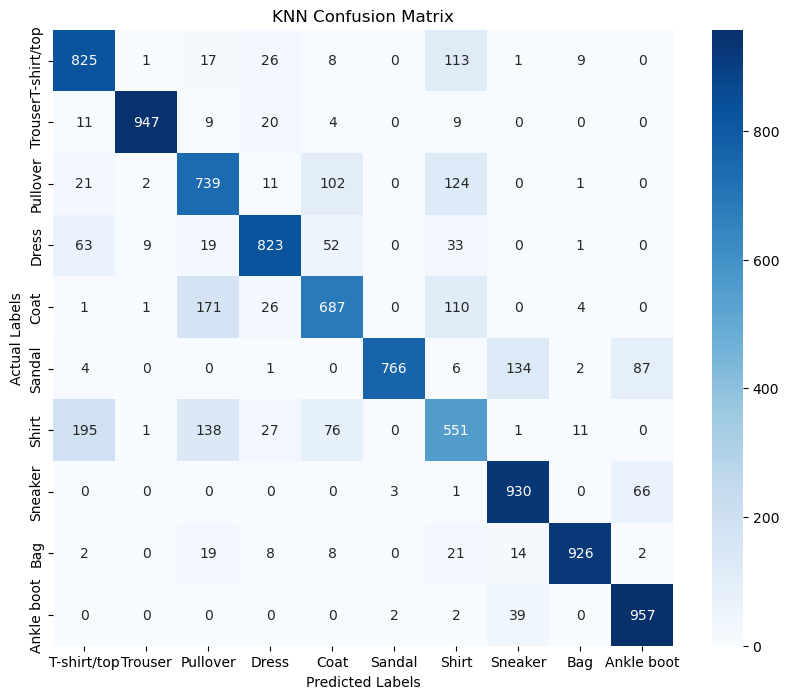

In [20]:
import seaborn as sns

cm = confusion_matrix(y_test, y_pred_knn)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names,
            yticklabels=class_names)

plt.xlabel("Predicted Labels")
plt.ylabel("Actual Labels")
plt.title("KNN Confusion Matrix")
plt.show()

In [21]:
dt_model = DecisionTreeClassifier(random_state=42)

dt_model.fit(X_train_flat, y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [22]:
y_pred_dt = dt_model.predict(X_test_flat)

print(y_pred_dt[:10])

[9 2 1 1 0 1 4 6 5 7]


In [23]:
dt_accuracy = accuracy_score(y_test, y_pred_dt)

print("Decision Tree Accuracy:", dt_accuracy * 100, "%")

Decision Tree Accuracy: 78.9 %


In [24]:
print(classification_report(
    y_test,
    y_pred_dt,
    target_names=class_names
))

              precision    recall  f1-score   support

 T-shirt/top       0.76      0.73      0.75      1000
     Trouser       0.96      0.95      0.95      1000
    Pullover       0.63      0.65      0.64      1000
       Dress       0.82      0.78      0.80      1000
        Coat       0.64      0.63      0.64      1000
      Sandal       0.90      0.89      0.89      1000
       Shirt       0.52      0.55      0.54      1000
     Sneaker       0.87      0.88      0.88      1000
         Bag       0.91      0.91      0.91      1000
  Ankle boot       0.90      0.91      0.91      1000

    accuracy                           0.79     10000
   macro avg       0.79      0.79      0.79     10000
weighted avg       0.79      0.79      0.79     10000



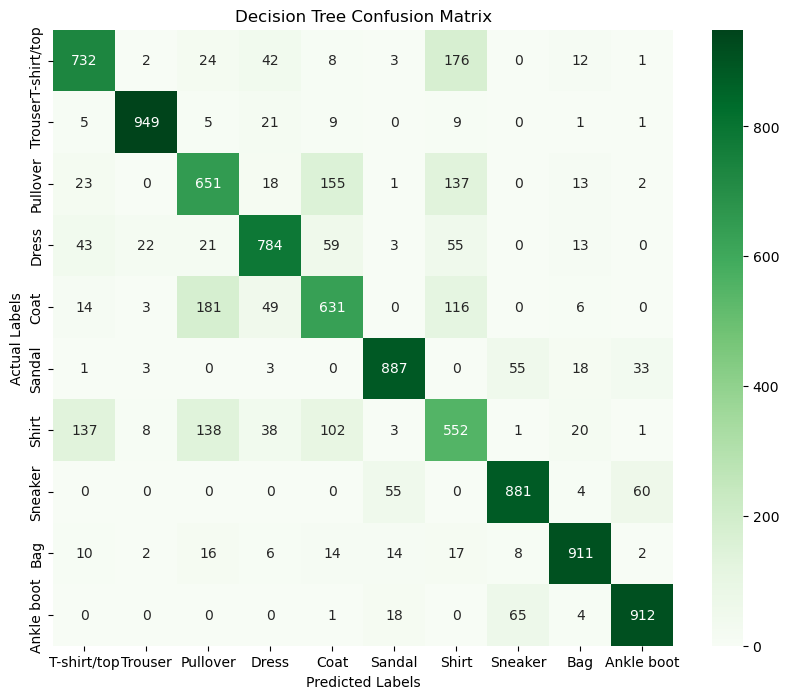

In [25]:
cm_dt = confusion_matrix(y_test, y_pred_dt)

plt.figure(figsize=(10, 8))
sns.heatmap(cm_dt, annot=True, fmt="d", cmap="Greens",
            xticklabels=class_names,
            yticklabels=class_names)

plt.xlabel("Predicted Labels")
plt.ylabel("Actual Labels")
plt.title("Decision Tree Confusion Matrix")
plt.show()

### Project conclusion
You can use this conclusion in your project:

"Both KNN and Decision Tree algorithms were implemented for Fashion Image Classification using the Fashion-MNIST dataset. KNN achieved 81.51% accuracy, while Decision Tree achieved 78.9%. KNN performed better than Decision Tree in this experiment. Both models classified trousers, bags and footwear more effectively, while they struggled to distinguish visually similar clothing categories."